# CFAR ship detection on xView3-SAR: a two-scene benchmark

Measures how well classic CFAR detectors (2D CA-CFAR, Hollow OS-CFAR, Two-Parameter CFAR) find vessels in Sentinel-1 VH imagery, using the human/automated labels of the xView3-SAR validation set.

**Protocol (read this first)**
- Detector parameters were chosen by looking at results on the *calibration* scene (scene 1). They were then kept fixed and run once on the *test* scene (scene 2). The thresholds were fixed before scene 2 was run; this note was written afterwards.
- Everything is evaluated only inside the water mask of the dataset (`owiMask == 0`, about 500 m resolution). Labelled vessels that fall on masked-out cells are counted and reported as *not evaluated*, not as misses.
- Predictions that match a labelled non-vessel object (or, in the HIGH-only table, a MEDIUM/LOW vessel) are ignored, not counted as false alarms. Unlabelled real objects are still counted as false alarms, so precision is a lower bound.
- Peak values found by sweeping thresholds on the same scene they are reported for are optimistic.

**Data (not included)** — download the xView3-SAR validation labels (`validation.csv`) and the two scenes from the official xView3 site under its terms, and extract each scene into a folder named after its scene id. Do not commit the data or any signed download links.

In [ ]:
!pip -q install rasterio scipy pandas matplotlib

## 1. Configuration and helper functions

In [ ]:
import os
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
from scipy.ndimage import (
    median_filter, percentile_filter, uniform_filter,
    label, find_objects, binary_closing,
)
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment

# ---------------------------------------------------------------------
# Locked configuration. Thresholds were chosen on scene 1 (calibration).
# ---------------------------------------------------------------------
CONFIG = {
    "data_dir": ".",                       # folder that contains one sub-folder per scene id
    "csv_path": "./validation.csv",
    "calibration_scene": "590dd08f71056cacv",   # scene 1: thresholds chosen here
    "test_scene": "b1844cde847a3942v",          # scene 2: run once with locked thresholds
    "crop_size": 6000,                     # window (pixels) centred on the median vessel position
    "nan_fill_db": -30.0,                  # value used for missing SAR pixels
    "brightness_floor_db": -30.0,          # absolute brightness cut-off (effectively off)
    "median_filter_size": 3,
    "closing_kernel": (5, 5),              # note: closing slightly erodes objects touching the window edge
    "min_cluster_area": 3,                 # minimum bounding-box area in pixels
    "match_distance_px": 20.0,             # matching radius (20 px = 200 m)

    "ca_guard_win": 9,
    "ca_bg_win": 25,
    "ca_locked_T_db": 11.6,                # scene-1 optimum was the grid point 11.571

    "os_guard_win": 9,
    "os_outer_win": 21,
    "os_percentile": 85,
    "os_locked_T_db": 8.1,                 # scene-1 optimum was the grid point 8.143

    "twoparam_locked_T_std": 5.5,
    "ref_low_T_db": 5.0,                   # low-threshold, high-recall reference point

    "db_sweep_grid": np.linspace(3.0, 15.0, 15),
    "std_sweep_grid": np.linspace(2.0, 9.0, 15),
}

import subprocess

def download_scene(scene_id, links_file="tiny.txt", data_dir="."):
    """Download and extract one scene quietly. The signed link is never printed."""
    if os.path.exists(os.path.join(data_dir, scene_id, "VH_dB.tif")):
        print(f"{scene_id}: already present")
        return
    with open(links_file) as f:
        urls = [l.strip() for l in f if l.strip().startswith("https://") and scene_id in l]
    if not urls:
        raise FileNotFoundError(f"{scene_id}: no link found in {links_file}")
    tar_path = os.path.join(data_dir, f"{scene_id}.tar.gz")
    try:
        subprocess.run(["wget", "-q", "-O", tar_path, urls[0]], check=True)
        subprocess.run(["tar", "-xzf", tar_path, "-C", data_dir], check=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"{scene_id}: download/extract failed (exit code {e.returncode}); "
                           "the signed link may have expired") from None
    finally:
        if os.path.exists(tar_path):
            os.remove(tar_path)
    print(f"{scene_id}: downloaded and extracted")

for sid in [CONFIG["calibration_scene"], CONFIG["test_scene"]]:
    download_scene(sid, data_dir=CONFIG["data_dir"])

def prepare_scene(df, scene_id, cfg):
    """Load a window of the scene, build detector background maps and ground-truth lists."""
    scene_dir = os.path.join(cfg["data_dir"], scene_id)
    rows = df[df["scene_id"] == scene_id].copy()
    vessels = rows[rows["is_vessel"] == True]
    med_r = int(vessels["detect_scene_row"].median())
    med_c = int(vessels["detect_scene_column"].median())
    crop = cfg["crop_size"]

    with rasterio.open(os.path.join(scene_dir, "VH_dB.tif")) as src:
        r_off = max(0, min(src.height - crop, med_r - crop // 2))
        c_off = max(0, min(src.width - crop, med_c - crop // 2))
        win = Window(c_off, r_off, crop, crop)
        vh_db = np.nan_to_num(src.read(1, window=win).astype(np.float32), nan=cfg["nan_fill_db"])
        full_w, full_h = src.width, src.height

    with rasterio.open(os.path.join(scene_dir, "owiMask.tif")) as owi:
        sx, sy = owi.width / full_w, owi.height / full_h
        owin = Window(c_off * sx, r_off * sy, crop * sx, crop * sy)
        water_mask = owi.read(1, window=owin, out_shape=(crop, crop)) == 0

    in_win = rows[
        (rows["detect_scene_row"] >= r_off) & (rows["detect_scene_row"] < r_off + crop) &
        (rows["detect_scene_column"] >= c_off) & (rows["detect_scene_column"] < c_off + crop)
    ].copy().reset_index(drop=True)
    in_win["local_row"] = in_win["detect_scene_row"] - r_off
    in_win["local_col"] = in_win["detect_scene_column"] - c_off
    ri = in_win["local_row"].astype(int).clip(0, crop - 1).values
    ci = in_win["local_col"].astype(int).clip(0, crop - 1).values
    in_win["in_water_mask"] = water_mask[ri, ci]

    win_vessels = in_win[in_win["is_vessel"] == True]
    water_rec = in_win[in_win["in_water_mask"]].reset_index(drop=True)
    eval_vessels = water_rec[water_rec["is_vessel"] == True].reset_index(drop=True)
    high = eval_vessels[eval_vessels["confidence"] == "HIGH"]

    cols = ["local_row", "local_col"]
    not_vessel = water_rec["is_vessel"] != True
    not_high = water_rec["confidence"] != "HIGH"

    # detector background maps
    vh_clean = median_filter(vh_db, size=cfg["median_filter_size"])
    bg_w, gd_w = cfg["ca_bg_win"], cfg["ca_guard_win"]
    n_bg = bg_w ** 2 - gd_w ** 2
    ca_bg = (uniform_filter(vh_clean, size=bg_w) * bg_w ** 2
             - uniform_filter(vh_clean, size=gd_w) * gd_w ** 2) / n_bg
    sq = (uniform_filter(vh_clean ** 2, size=bg_w) * bg_w ** 2
          - uniform_filter(vh_clean ** 2, size=gd_w) * gd_w ** 2) / n_bg
    ca_std = np.sqrt(np.maximum(sq - ca_bg ** 2, 1e-4))

    out_w, os_gd = cfg["os_outer_win"], cfg["os_guard_win"]
    fp = np.ones((out_w, out_w), dtype=bool)
    pad = (out_w - os_gd) // 2
    fp[pad:pad + os_gd, pad:pad + os_gd] = False
    os_bg = percentile_filter(vh_clean, percentile=cfg["os_percentile"], footprint=fp)

    return {
        "scene_id": scene_id, "vh_clean": vh_clean, "ca_bg": ca_bg, "ca_std": ca_std,
        "os_bg": os_bg, "water_mask": water_mask,
        "n_window": len(win_vessels), "n_masked": int((~win_vessels["in_water_mask"]).sum()),
        "n_eval": len(eval_vessels), "n_high": len(high),
        "gt_all": eval_vessels[cols].values, "ig_all": water_rec[not_vessel][cols].values,
        "gt_high": high[cols].values, "ig_high": water_rec[not_vessel | not_high][cols].values,
    }


def extract_centroids(binary_mask, water_mask, cfg):
    """Closing + connected components; returns one centroid per candidate."""
    clean = binary_closing(binary_mask & water_mask, structure=np.ones(cfg["closing_kernel"]))
    lbl, _ = label(clean)
    pts = []
    for box in find_objects(lbl):
        area = (box[0].stop - box[0].start) * (box[1].stop - box[1].start)
        if area >= cfg["min_cluster_area"]:
            pts.append([(box[0].start + box[0].stop) / 2.0, (box[1].start + box[1].stop) / 2.0])
    return np.array(pts) if pts else np.empty((0, 2))


def wilson_ci(k, n, z=1.96):
    if n == 0:
        return 0.0, 0.0
    p = k / n
    denom = 1.0 + z ** 2 / n
    center = (p + z ** 2 / (2.0 * n)) / denom
    half = z * np.sqrt(p * (1.0 - p) / n + z ** 2 / (4.0 * n ** 2)) / denom
    return max(0.0, center - half), min(1.0, center + half)


def evaluate_predictions(pred, target_gt, ignore_gt, max_dist=20.0):
    """One-to-one matching. Predictions near an 'ignore' object are not counted as false alarms."""
    if len(pred) == 0:
        return 0, 0, len(target_gt), 0.0, 0.0, 0.0
    if len(target_gt) == 0:
        return 0, len(pred), 0, 0.0, 0.0, 0.0
    d = cdist(pred, target_gt)
    p_idx, g_idx = linear_sum_assignment(d)
    matched = {p for p, g in zip(p_idx, g_idx) if d[p, g] <= max_dist}
    rest = [i for i in range(len(pred)) if i not in matched]
    ignored = 0
    if rest and len(ignore_gt) > 0:
        ignored = int((cdist(pred[rest], ignore_gt).min(axis=1) <= max_dist).sum())
    tp, fp = len(matched), len(rest) - ignored
    fn = len(target_gt) - tp
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return tp, fp, fn, prec, rec, f1


def detect(S, algo, T, cfg):
    """Binary detection mask for one algorithm at threshold T."""
    thr = algo["bg"] + (T * algo["std"] if algo["std"] is not None else T)
    return (S["vh_clean"] > thr) & (S["vh_clean"] > cfg["brightness_floor_db"])


def algo_table(S, cfg):
    return {
        "2D CA-CFAR": dict(bg=S["ca_bg"], std=None, grid=cfg["db_sweep_grid"],
                           locked=cfg["ca_locked_T_db"], ref=cfg["ref_low_T_db"], color="tab:red"),
        "Hollow OS-CFAR": dict(bg=S["os_bg"], std=None, grid=cfg["db_sweep_grid"],
                               locked=cfg["os_locked_T_db"], ref=cfg["ref_low_T_db"], color="tab:cyan"),
        "Two-Param CFAR": dict(bg=S["ca_bg"], std=S["ca_std"], grid=cfg["std_sweep_grid"],
                               locked=cfg["twoparam_locked_T_std"], ref=None, color="tab:orange"),
    }


def eval_both(S, pts, cfg):
    md_ = cfg["match_distance_px"]
    return (evaluate_predictions(pts, S["gt_all"], S["ig_all"], md_),
            evaluate_predictions(pts, S["gt_high"], S["ig_high"], md_))


def print_table(title, rows):
    print(title)
    print("-" * 104)
    print(f"{'OPERATING POINT':<36}| {'TP':<4}| {'FP':<5}| {'FN':<4}| {'PRECISION (95% CI)':<22}| {'RECALL (95% CI)':<22}| F1")
    print("-" * 104)
    for name, (tp, fp, fn, prec, rec, f1) in rows:
        pl, ph = wilson_ci(tp, tp + fp)
        rl, rh = wilson_ci(tp, tp + fn)
        print(f"{name:<36}| {tp:<4}| {fp:<5}| {fn:<4}| {prec*100:5.1f}% ({pl*100:4.1f}-{ph*100:4.1f})  "
              f"| {rec*100:5.1f}% ({rl*100:4.1f}-{rh*100:4.1f})  | {f1*100:5.1f}%")
    print()


590dd08f71056cacv: downloaded and extracted
b1844cde847a3942v: downloaded and extracted


## 2. Locked operating points on both scenes

Scene 1 numbers are *in-sample* (the thresholds were chosen there). Scene 2 numbers are the out-of-sample test.

In [ ]:
df_val = pd.read_csv(CONFIG["csv_path"])
SCENES = {}

for role, sid in [("SCENE 1 - calibration (in-sample)", CONFIG["calibration_scene"]),
                  ("SCENE 2 - test (out-of-sample)", CONFIG["test_scene"])]:
    S = prepare_scene(df_val, sid, CONFIG)
    SCENES[sid] = S
    print("=" * 104)
    print(f"{role}: {sid}")
    print(f"Labelled vessels in window: {S['n_window']} | on masked-out cells (not evaluated): {S['n_masked']} "
          f"| evaluated: {S['n_eval']} (HIGH confidence: {S['n_high']})")
    print("=" * 104)

    rows_all, rows_high = [], []
    for name, a in algo_table(S, CONFIG).items():
        points = [(f"{name} (locked T={a['locked']})", a["locked"])]
        if a["ref"] is not None:
            points.append((f"{name} (ref T={a['ref']})", a["ref"]))
        for pname, T in points:
            pts = extract_centroids(detect(S, a, T, CONFIG), S["water_mask"], CONFIG)
            res_all, res_high = eval_both(S, pts, CONFIG)
            rows_all.append((pname, res_all))
            rows_high.append((pname, res_high))
    print_table(f"ALL EVALUATED VESSELS (N={S['n_eval']})", rows_all)
    print_table(f"HIGH-CONFIDENCE LABELS ONLY (N={S['n_high']}); MEDIUM/LOW vessels and non-vessels ignored", rows_high)

SCENE 1 - calibration (in-sample): 590dd08f71056cacv
Labelled vessels in window: 214 | on masked-out cells (not evaluated): 98 | evaluated: 116 (HIGH confidence: 77)
ALL EVALUATED VESSELS (N=116)
--------------------------------------------------------------------------------------------------------
OPERATING POINT                     | TP  | FP   | FN  | PRECISION (95% CI)    | RECALL (95% CI)       | F1
--------------------------------------------------------------------------------------------------------
2D CA-CFAR (locked T=11.6)          | 96  | 8    | 20  |  92.3% (85.6-96.1)  |  82.8% (74.9-88.6)  |  87.3%
2D CA-CFAR (ref T=5.0)              | 112 | 177  | 4   |  38.8% (33.3-44.5)  |  96.6% (91.5-98.7)  |  55.3%
Hollow OS-CFAR (locked T=8.1)       | 100 | 24   | 16  |  80.6% (72.8-86.6)  |  86.2% (78.8-91.3)  |  83.3%
Hollow OS-CFAR (ref T=5.0)          | 107 | 58   | 9   |  64.8% (57.3-71.7)  |  92.2% (85.9-95.9)  |  76.2%
Two-Param CFAR (locked T=5.5)       | 40  | 30   | 76 

## 3. Threshold sweeps (precision-recall) and threshold drift

Stars mark the locked operating points. The best point on a sweep is chosen on the same scene it is reported for, so it is an optimistic upper bound.

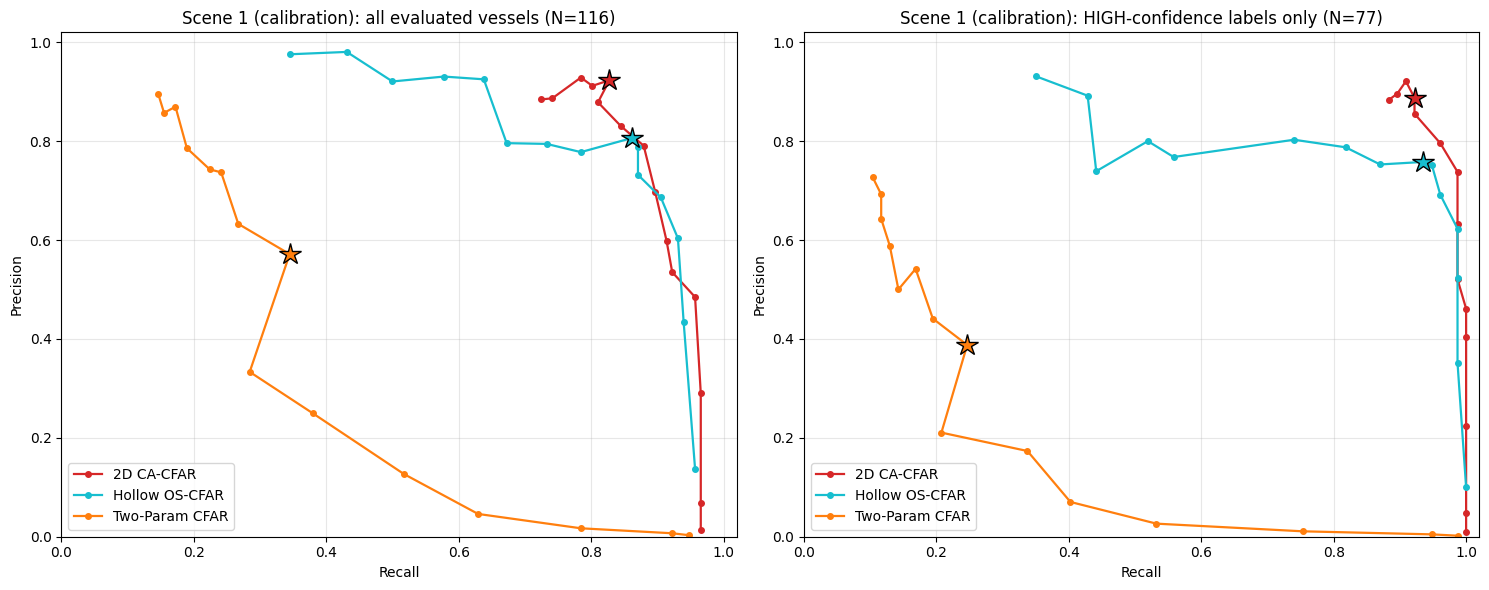

Scene 1 (calibration): locked threshold vs. best threshold on this scene (all evaluated vessels)
  2D CA-CFAR       locked T= 11.6 -> F1  87.3% | best-on-this-scene T= 11.6 -> F1  87.3% (optimistic)
  Hollow OS-CFAR   locked T=  8.1 -> F1  83.3% | best-on-this-scene T=  8.1 -> F1  83.3% (optimistic)
  Two-Param CFAR   locked T=  5.5 -> F1  43.0% | best-on-this-scene T=  5.5 -> F1  43.0% (optimistic)



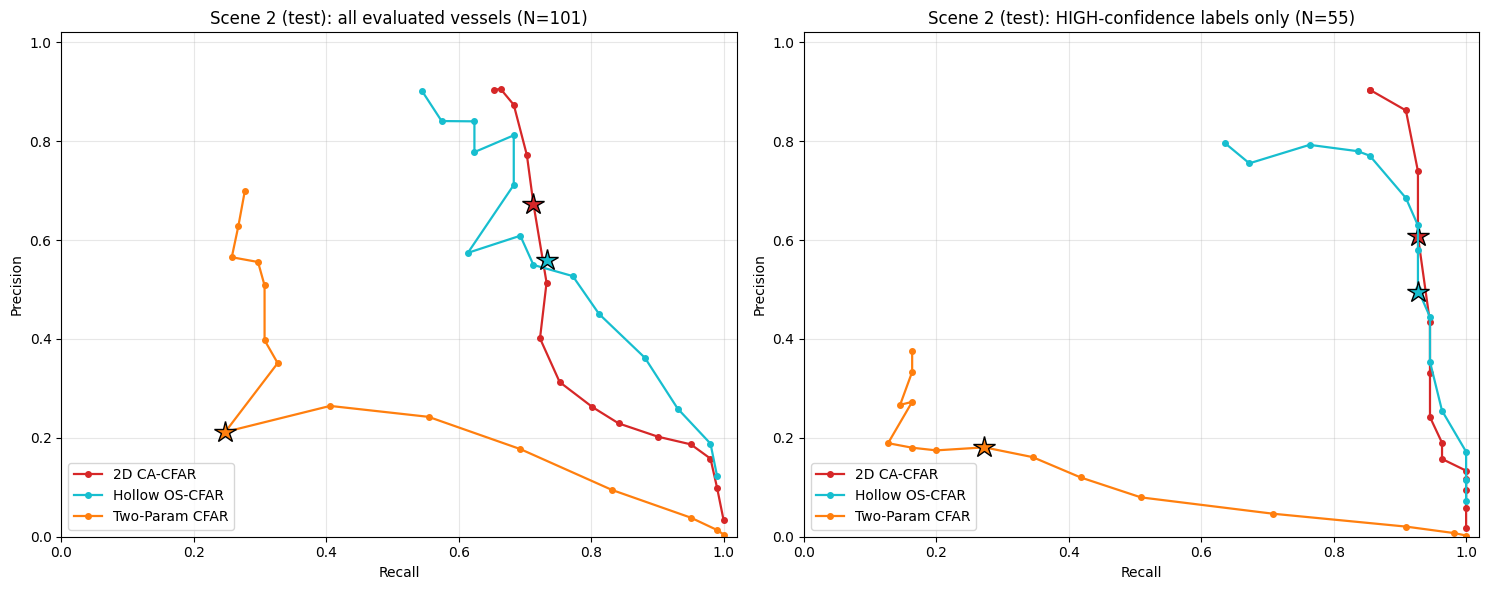

Scene 2 (test): locked threshold vs. best threshold on this scene (all evaluated vessels)
  2D CA-CFAR       locked T= 11.6 -> F1  69.2% | best-on-this-scene T= 13.3 -> F1  76.7% (optimistic)
  Hollow OS-CFAR   locked T=  8.1 -> F1  63.5% | best-on-this-scene T= 11.6 -> F1  74.2% (optimistic)
  Two-Param CFAR   locked T=  5.5 -> F1  22.8% | best-on-this-scene T=  9.0 -> F1  39.7% (optimistic)



In [ ]:
for role, sid in [("Scene 1 (calibration)", CONFIG["calibration_scene"]),
                  ("Scene 2 (test)", CONFIG["test_scene"])]:
    S = SCENES[sid]
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    drift = []
    for name, a in algo_table(S, CONFIG).items():
        curve_all, curve_high, best = [], [], (-1, None)
        for T in a["grid"]:
            pts = extract_centroids(detect(S, a, T, CONFIG), S["water_mask"], CONFIG)
            r_all, r_high = eval_both(S, pts, CONFIG)
            curve_all.append((r_all[4], r_all[3]))      # (recall, precision)
            curve_high.append((r_high[4], r_high[3]))
            if r_all[5] > best[0]:
                best = (r_all[5], T)
        lp = extract_centroids(detect(S, a, a["locked"], CONFIG), S["water_mask"], CONFIG)
        l_all, l_high = eval_both(S, lp, CONFIG)
        for ax, curve, lk in [(axes[0], curve_all, l_all), (axes[1], curve_high, l_high)]:
            xs, ys = zip(*curve)
            ax.plot(xs, ys, marker="o", ms=4, lw=1.6, color=a["color"], label=name)
            ax.plot(lk[4], lk[3], marker="*", ms=16, color=a["color"], mec="black", ls="none")
        drift.append((name, a["locked"], l_all[5], best[1], best[0]))
    axes[0].set_title(f"{role}: all evaluated vessels (N={S['n_eval']})")
    axes[1].set_title(f"{role}: HIGH-confidence labels only (N={S['n_high']})")
    for ax in axes:
        ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
        ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend(loc="lower left")
    plt.tight_layout()
    plt.savefig(f"pr_curves_{sid}.png", dpi=150)
    plt.show()
    print(f"{role}: locked threshold vs. best threshold on this scene (all evaluated vessels)")
    for name, lt, lf1, bt, bf1 in drift:
        print(f"  {name:<16} locked T={lt:5.1f} -> F1 {lf1*100:5.1f}% | best-on-this-scene T={bt:5.1f} -> F1 {bf1*100:5.1f}% (optimistic)")
    print()

## 4. How to read these results

- Two scenes with roughly 100 evaluated vessels each: confidence intervals are wide, and differences of a few F1 points are within noise.
- Roughly half of the labelled vessels in each window sit on cells of the coarse water mask that are marked as land. The results above say nothing about them (near-shore and harbour areas are not evaluated).
- The optimal threshold moved between scenes, so a fixed dB threshold does not transfer reliably.
- This notebook measures detection only. It does not evaluate any AIS-based "dark vessel" logic, and the label column `source` should not be read as "AIS on/off".
- Numbers are not comparable with the official xView3 leaderboard (different subset, own matching rule, scoring code not used).